# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(28)

In [2]:
CSV_NAME = "practical_module_dataset.csv"
CSV_URL = (
    "https://raw.githubusercontent.com/radif-ru/applied-statistics/main/data/"
    + CSV_NAME
)
# файл рядом с ноутбуком (как в задании), в data/ репозитория или — в Colab — по ссылке
local = next(
    (p for p in (Path(CSV_NAME), Path("../data") / CSV_NAME) if p.exists()), None
)
df = pd.read_csv(local or CSV_URL)
print(df.shape)
df.head()

(30, 8)


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

Типы столбцов: {'id': 'int64', 'age': 'int64', 'height_cm': 'float64', 'weight_kg': 'float64', 'iq': 'int64', 'tv_hours': 'int64', 'study_hours': 'float64', 'score': 'float64'}
Пропуски: {'id': 0, 'age': 0, 'height_cm': 0, 'weight_kg': 0, 'iq': 0, 'tv_hours': 0, 'study_hours': 0, 'score': 0}
Повторы id: 0


,count,mean,std,min,25%,50%,75%,max,skew,outliers_iqr
id,30.0,15.50,8.80,1.00,8.25,15.50,22.75,30.00,0.00,0
age,30.0,29.40,6.67,18.00,24.25,29.00,35.50,39.00,-0.09,0
height_cm,30.0,169.15,9.58,148.20,163.25,169.75,174.10,185.80,-0.27,0
weight_kg,30.0,62.73,9.20,44.75,56.62,63.68,68.60,81.13,-0.09,0
iq,30.0,100.43,12.12,82.00,91.00,97.00,109.75,132.00,0.88,0
tv_hours,30.0,12.27,3.83,6.00,9.00,12.00,14.00,22.00,0.88,2
study_hours,30.0,7.64,3.28,2.70,4.98,7.65,9.45,14.40,0.21,0
score,30.0,73.40,8.25,58.90,67.80,74.30,78.73,91.50,0.14,0


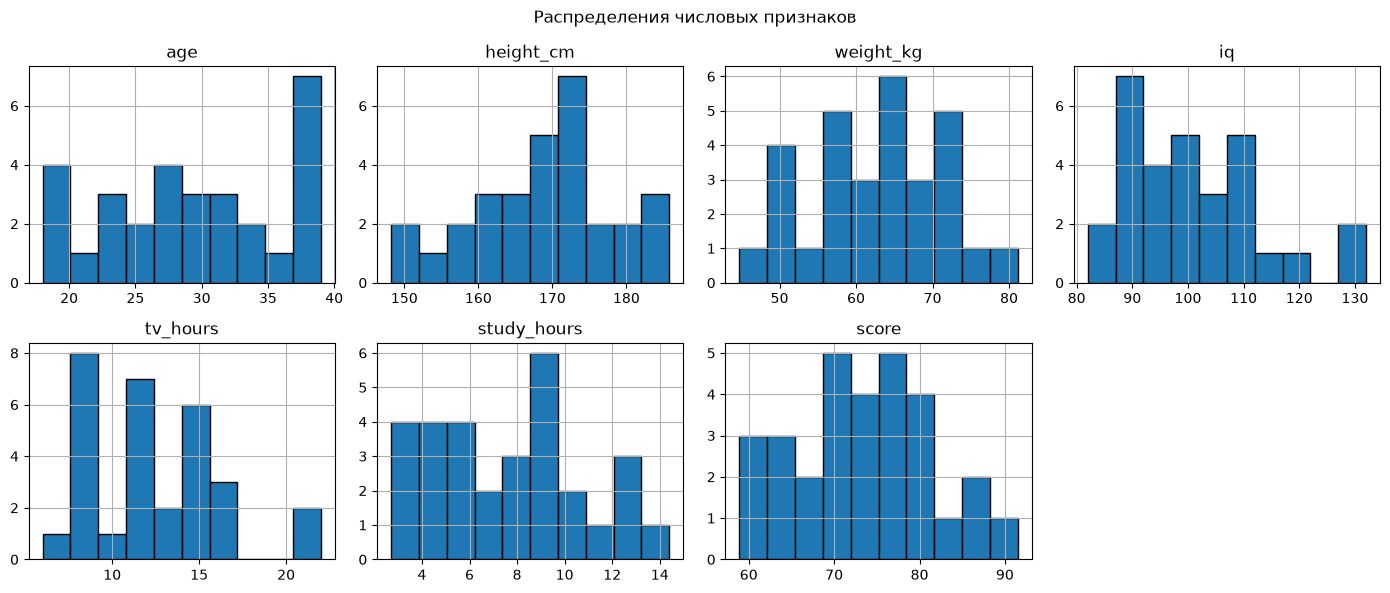

In [3]:
print("Типы столбцов:", df.dtypes.astype(str).to_dict())
print("Пропуски:", df.isna().sum().to_dict())
print("Повторы id:", df["id"].duplicated().sum())

features = df.columns.drop("id")  # id — номер записи, а не признак
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outside = (df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)

summary = df.describe().T
summary["skew"] = df.skew()
summary["outliers_iqr"] = outside.sum()
display(summary.round(2))

df[features].hist(bins=10, figsize=(14, 6), layout=(2, 4), edgecolor="black")
plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.show()

**Вывод:** 30 наблюдений, 8 числовых столбцов (int64/float64), пропусков и повторов id нет. Рост, вес, возраст, score и study_hours распределены почти симметрично (|skew| $\le 0.27$); у iq и tv_hours заметная правая асимметрия (skew $\approx 0.88$) — правый хвост из нескольких больших значений (iq до 132, tv_hours до 22). По правилу 1.5·IQR выбросы есть только у tv_hours (2 значения по 22 ч), в остальных признаках их нет.

### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

In [4]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

In [5]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

In [6]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

In [7]:
# ВАШЕ РЕШЕНИЕ

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

In [8]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

In [9]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

In [10]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

In [11]:
# ВАШЕ РЕШЕНИЕ

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

In [12]:
# ВАШЕ РЕШЕНИЕ

**Вывод:** <ВАШ ОТВЕТ>